In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install teachopencadd --no-deps -q
    !teachopencadd -d 13
    %pip uninstall teachopencadd -y -q
    %pip install -qr requirements.txt

In [2]:
import time
from pathlib import Path
from urllib.parse import quote

from IPython.display import Markdown, Image, HTML
import requests
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Chem.Draw import MolsToGridImage

In [3]:
# Get PubChem CID by name
name = "aspirin"

url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{name}/cids/JSON"

r = requests.get(url)
r.raise_for_status()
response = r.json()
if "IdentifierList" in response:
    cid = response["IdentifierList"]["CID"][0]
else:
    raise ValueError(f"Could not find matches for compound: {name}")
print(f"PubChem CID for {name} is:\n{cid}")
# NBVAL_CHECK_OUTPUT

PubChem CID for aspirin is:
2244


In [4]:
# Get mol weight for aspirin
url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/property/MolecularWeight/JSON"

r = requests.get(url)
r.raise_for_status()
response = r.json()

if "PropertyTable" in response:
    mol_weight = response["PropertyTable"]["Properties"][0]["MolecularWeight"]
else:
    raise ValueError(f"Could not find matches for PubChem CID: {cid}")
print(f"Molecular weight for {name} is:\n{mol_weight}")
# NBVAL_CHECK_OUTPUT

Molecular weight for aspirin is:
180.16


The 2D structure of Aspirin:

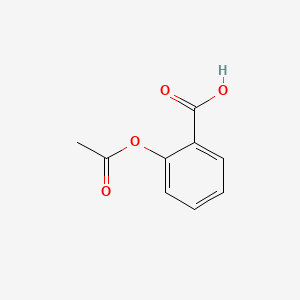

In [5]:
# Get PNG image from PubChem
url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/PNG"

r = requests.get(url)
r.raise_for_status()

display(Markdown("The 2D structure of Aspirin:"))
display(Image(r.content))

The structure of Gefitinib:


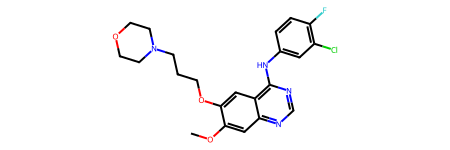

In [6]:
query = "COC1=C(C=C2C(=C1)N=CN=C2NC3=CC(=C(C=C3)F)Cl)OCCCN4CCOCC4"  # Gefitinib
print("The structure of Gefitinib:")
Chem.MolFromSmiles(query)

In [7]:
def query_pubchem_for_similar_compounds(smiles, threshold=75, n_records=10):
    """
    Query PubChem for similar compounds and return the job key.

    Parameters
    ----------
    smiles : str
        The canonical SMILES string for the given compound.
    threshold : int
        The threshold of similarity, default 75%. In PubChem, the default threshold is 90%.
    n_records : int
        The maximum number of feedback records.

    Returns
    -------
    str
        The job key from the PubChem web service.
    """
    escaped_smiles = quote(smiles).replace("/", ".")
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/similarity/smiles/{escaped_smiles}/JSON?Threshold={threshold}&MaxRecords={n_records}"
    r = requests.get(url)
    r.raise_for_status()
    key = r.json()["Waiting"]["ListKey"]
    return key

In [8]:
job_key = query_pubchem_for_similar_compounds(query)
job_key

'518924163884935131'

In [9]:
def check_and_download(key, attempts=30):
    """
    Check job status and download PubChem CIDs when the job finished

    Parameters
    ----------
    key : str
        The job key of the PubChem service.
    attempts : int
        The time waiting for the feedback from the PubChem service.

    Returns
    -------
    list
        The PubChem CIDs of similar compounds.
    """
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/listkey/{key}/cids/JSON"
    print(f"Querying for job {key} at URL {url}...", end="")
    while attempts:
        r = requests.get(url)
        r.raise_for_status()
        response = r.json()
        if "IdentifierList" in response:
            cids = response["IdentifierList"]["CID"]
            break
        attempts -= 1
        print(".", end="")
        time.sleep(10)
    else:
        raise ValueError(f"Could not find matches for job key: {key}")
    return cids

In [ ]:
similar_cids = check_and_download(job_key)

In [10]:
similar_cids = [2092, 176870, 208908, 3081361, 3157, 4893, 5401, 5583, 123631, 68546]

#bypass timeout for check and download function

In [11]:
similar_cids

[2092, 176870, 208908, 3081361, 3157, 4893, 5401, 5583, 123631, 68546]

In [12]:
def smiles_from_pubchem_cids(cids):
    """
    Get the canonical SMILES string from the PubChem CIDs.

    Parameters
    ----------
    cids : list
        A list of PubChem CIDs.

    Returns
    -------
    list
        The canonical SMILES strings of the PubChem CIDs.
    """
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{','.join(map(str, cids))}/property/CanonicalSMILES/JSON"
    r = requests.get(url)
    r.raise_for_status()
    return [item.get("ConnectivitySMILES") for item in r.json()["PropertyTable"]["Properties"]]

In [13]:
similar_smiles = smiles_from_pubchem_cids(similar_cids)

In [14]:
similar_smiles

['CN(CCCNC(=O)C1CCCO1)C2=NC3=CC(=C(C=C3C(=N2)N)OC)OC',
 'COCCOC1=C(C=C2C(=C1)C(=NC=N2)NC3=CC=CC(=C3)C#C)OCCOC',
 'CS(=O)(=O)CCNCC1=CC=C(O1)C2=CC3=C(C=C2)N=CN=C3NC4=CC(=C(C=C4)OCC5=CC(=CC=C5)F)Cl',
 'CN1CCC(CC1)COC2=C(C=C3C(=C2)N=CN=C3NC4=C(C=C(C=C4)Br)F)OC',
 'COC1=C(C=C2C(=C1)C(=NC(=N2)N3CCN(CC3)C(=O)C4COC5=CC=CC=C5O4)N)OC',
 'COC1=C(C=C2C(=C1)C(=NC(=N2)N3CCN(CC3)C(=O)C4=CC=CO4)N)OC',
 'COC1=C(C=C2C(=C1)C(=NC(=N2)N3CCN(CC3)C(=O)C4CCCO4)N)OC',
 'CC1=C(C=CC2=C1C(=NC(=N2)N)N)CNC3=CC(=C(C(=C3)OC)OC)OC',
 'COC1=C(C=C2C(=C1)N=CN=C2NC3=CC(=C(C=C3)F)Cl)OCCCN4CCOCC4',
 'COC1=C(C=C2C(=C1)C(=NC(=N2)N3CCN(CC3)C(=O)C4=CC=CO4)N)OC.Cl']

In [15]:
query_results_df = pd.DataFrame({"smiles": similar_smiles, "CIDs": similar_cids})
# 2. FIX: Filter the DataFrame to remove any rows where the 'smiles' value is None.
# This prevents RDKit from trying to process an invalid input.
query_results_df.dropna(subset=["smiles"], inplace=True)
PandasTools.AddMoleculeColumnToFrame(query_results_df, smilesCol="smiles")
query_results_df.head(5)

,smiles,CIDs,ROMol
0,CN(CCCNC(=O)C1CCCO1)C2=NC3=CC(=C(C=C3C(=N2)N)O...,2092,<rdkit.Chem.rdchem.Mol object at 0x16a4d92a0>
1,COCCOC1=C(C=C2C(=C1)C(=NC=N2)NC3=CC=CC(=C3)C#C...,176870,<rdkit.Chem.rdchem.Mol object at 0x16a4d9310>
2,CS(=O)(=O)CCNCC1=CC=C(O1)C2=CC3=C(C=C2)N=CN=C3...,208908,<rdkit.Chem.rdchem.Mol object at 0x16a4d9380>
3,CN1CCC(CC1)COC2=C(C=C3C(=C2)N=CN=C3NC4=C(C=C(C...,3081361,<rdkit.Chem.rdchem.Mol object at 0x16a4d93f0>
4,COC1=C(C=C2C(=C1)C(=NC(=N2)N3CCN(CC3)C(=O)C4CO...,3157,<rdkit.Chem.rdchem.Mol object at 0x16a4d9460>


,smiles,CIDs,ROMol
0,CN(CCCNC(=O)C1CCCO1)C2=NC3=CC(=C(C=C3C(=N2)N)O...,2092,
1,COCCOC1=C(C=C2C(=C1)C(=NC=N2)NC3=CC=CC(=C3)C#C...,176870,
2,CS(=O)(=O)CCNCC1=CC=C(O1)C2=CC3=C(C=C2)N=CN=C3...,208908,
3,CN1CCC(CC1)COC2=C(C=C3C(=C2)N=CN=C3NC4=C(C=C(C...,3081361,
4,COC1=C(C=C2C(=C1)C(=NC(=N2)N3CCN(CC3)C(=O)C4CO...,3157,
5,COC1=C(C=C2C(=C1)C(=NC(=N2)N3CCN(CC3)C(=O)C4=C...,4893,
6,COC1=C(C=C2C(=C1)C(=NC(=N2)N3CCN(CC3)C(=O)C4CC...,5401,
7,CC1=C(C=CC2=C1C(=NC(=N2)N)N)CNC3=CC(=C(C(=C3)O...,5583,
8,COC1=C(C=C2C(=C1)N=CN=C2NC3=CC(=C(C=C3)F)Cl)OC...,123631,
9,COC1=C(C=C2C(=C1)C(=NC(=N2)N3CCN(CC3)C(=O)C4=C...,68546,

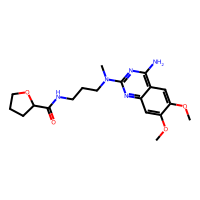
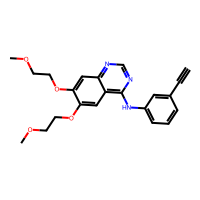
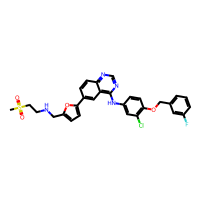
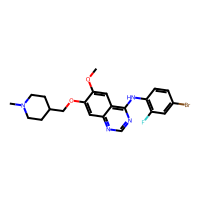
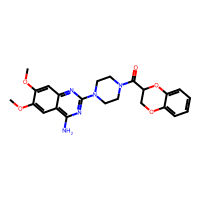
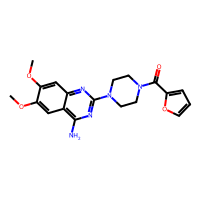
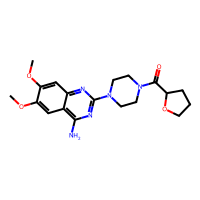
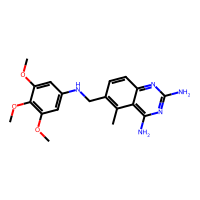
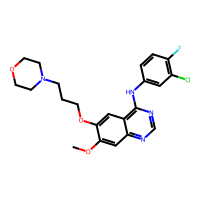
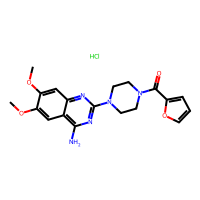

In [16]:
query_results_df